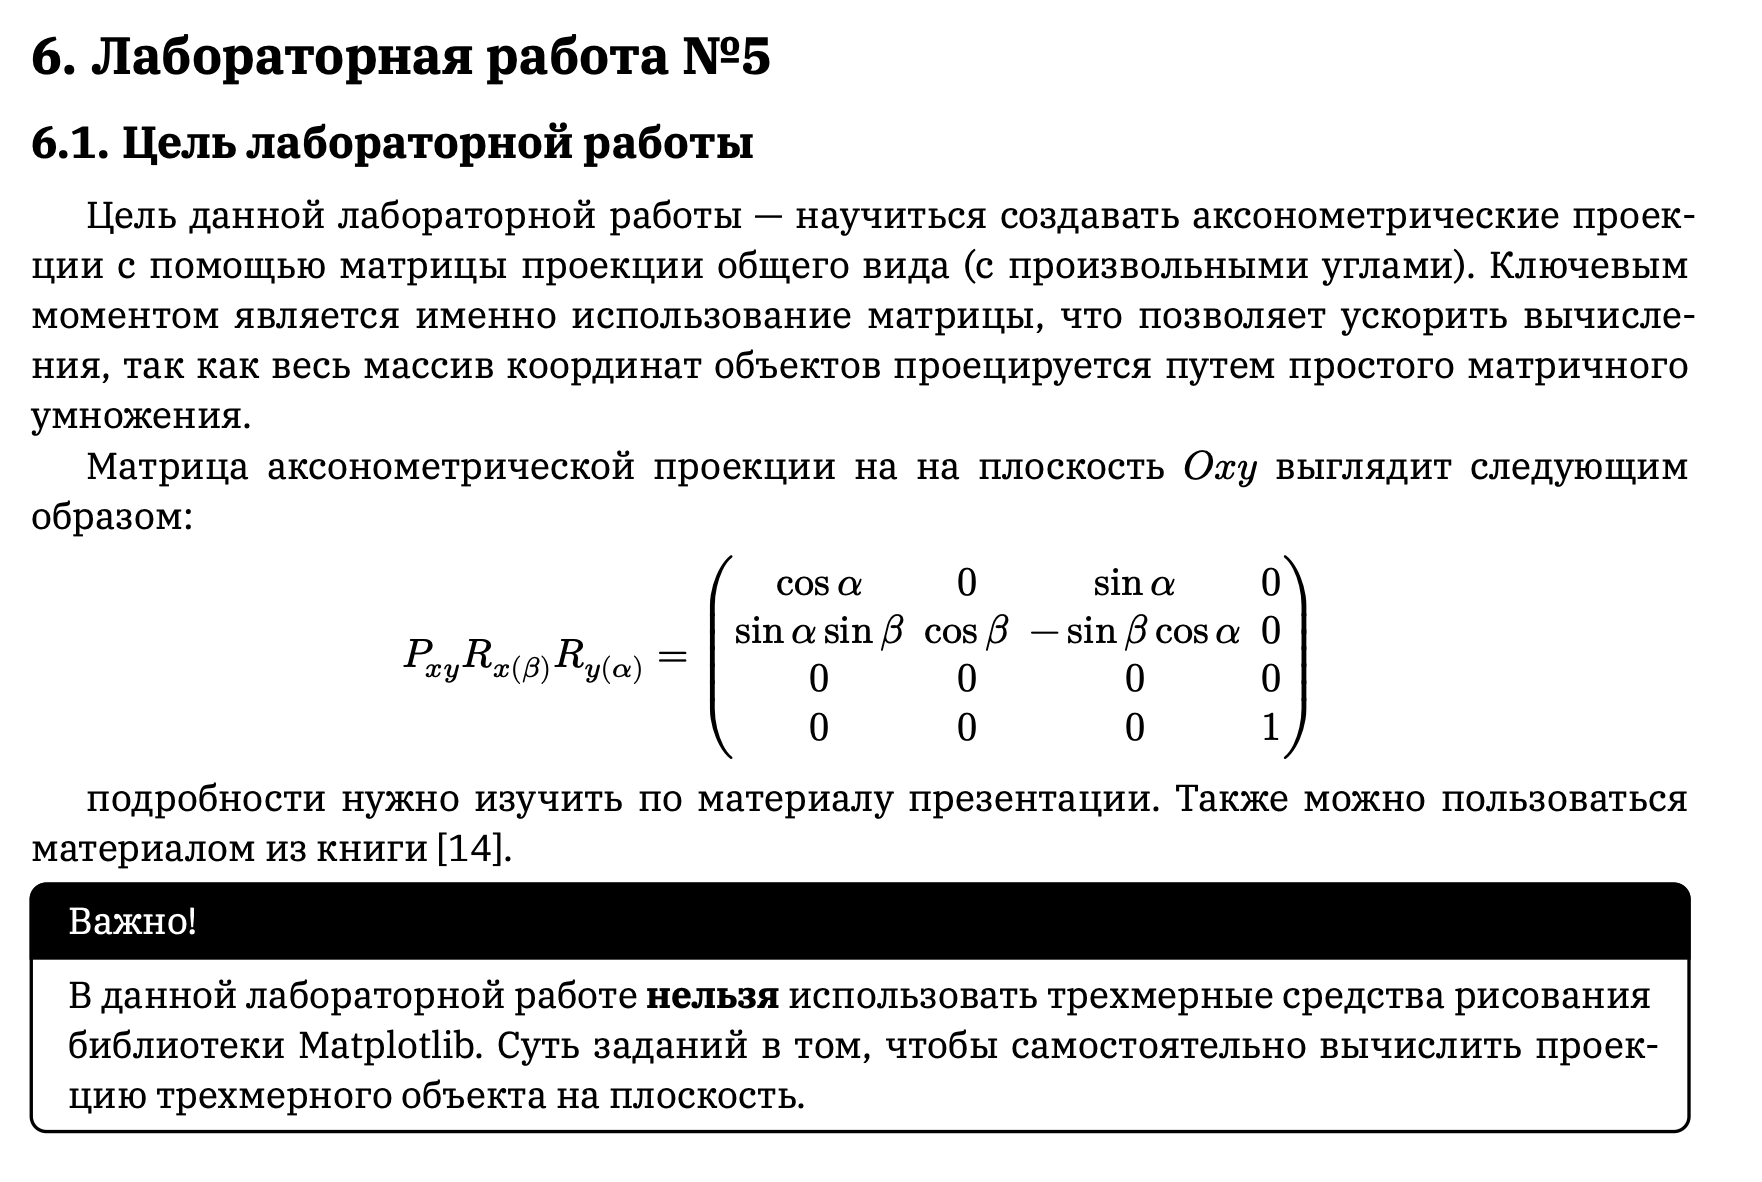

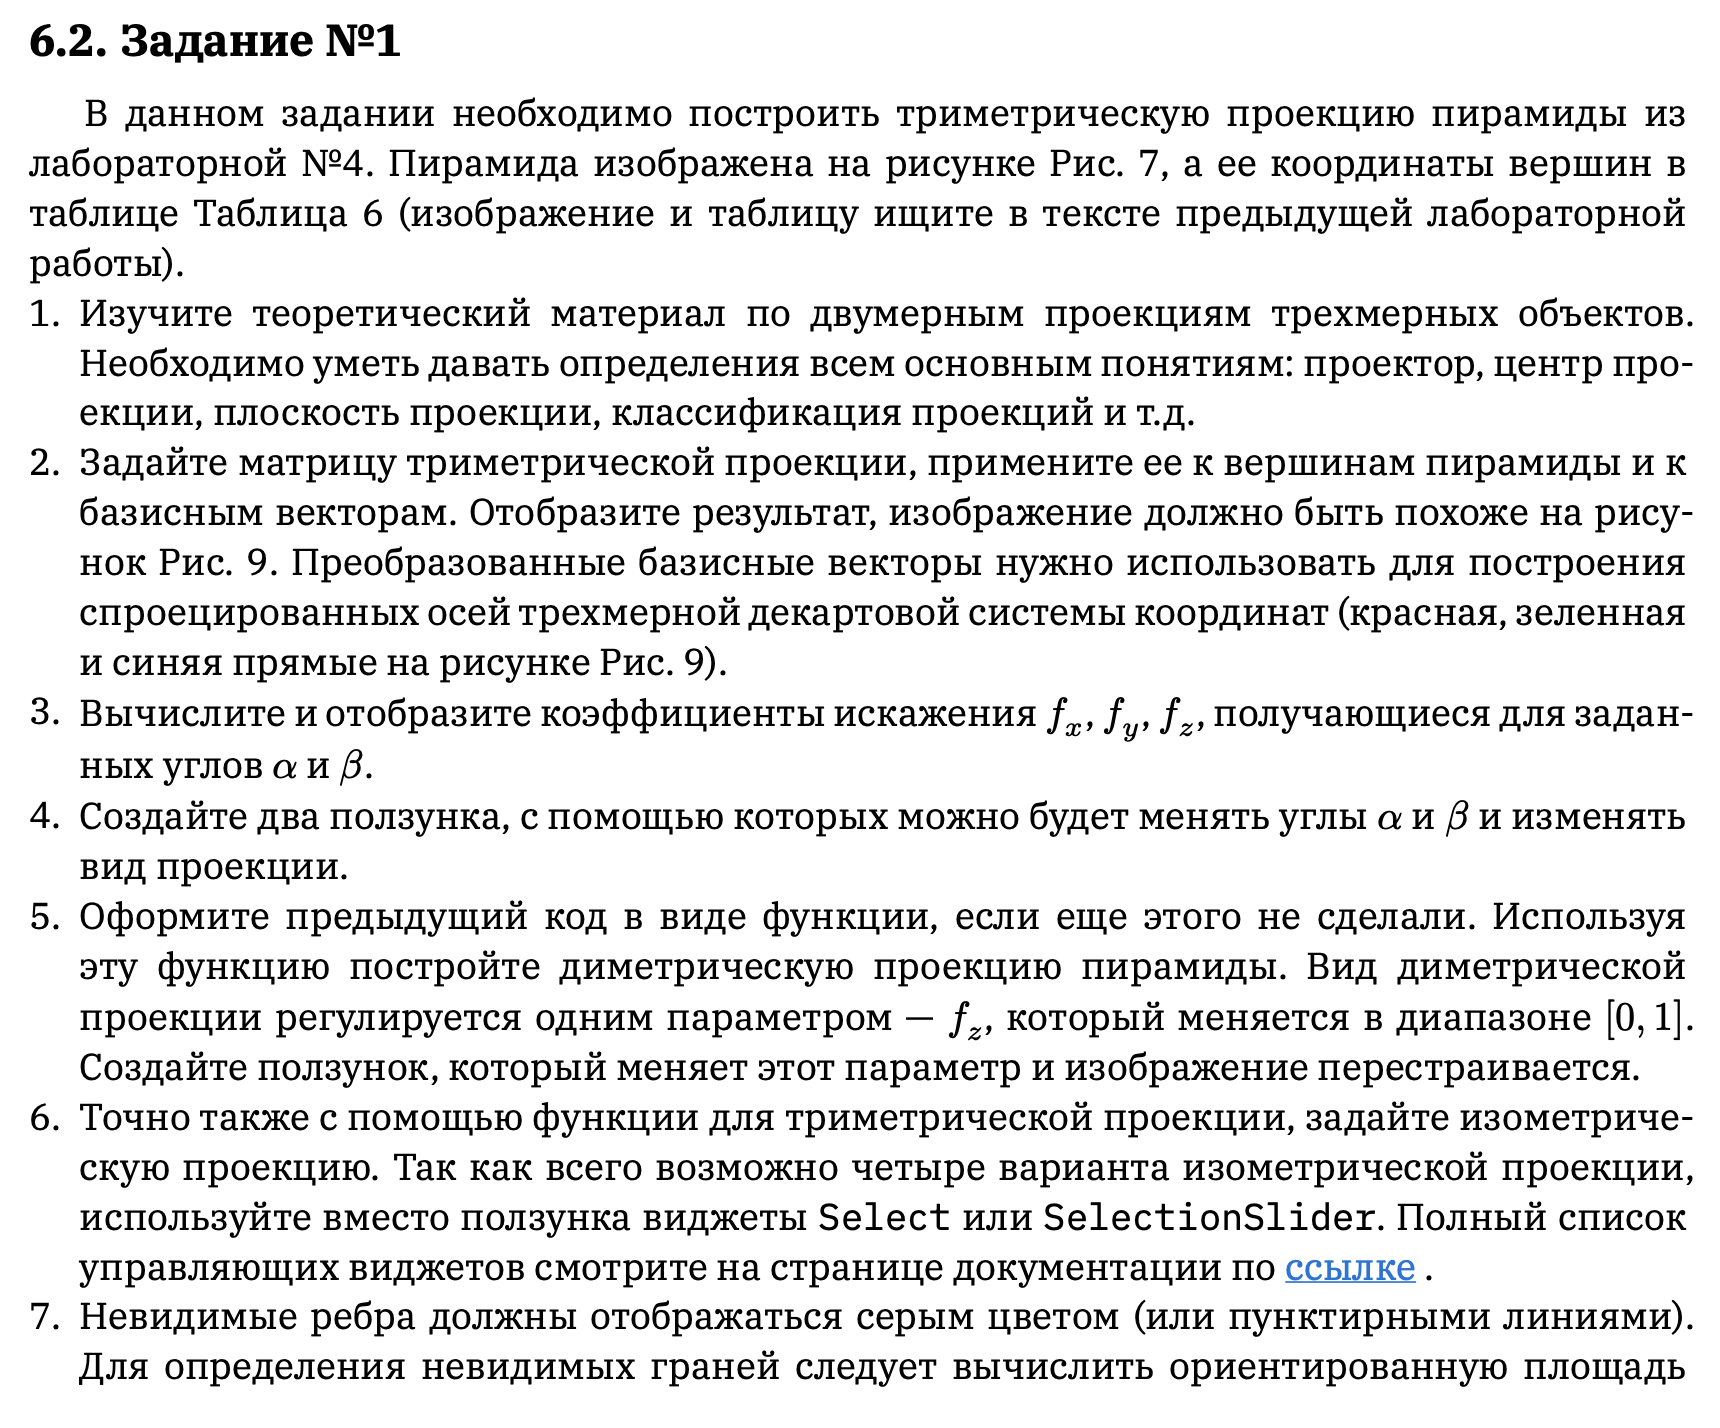
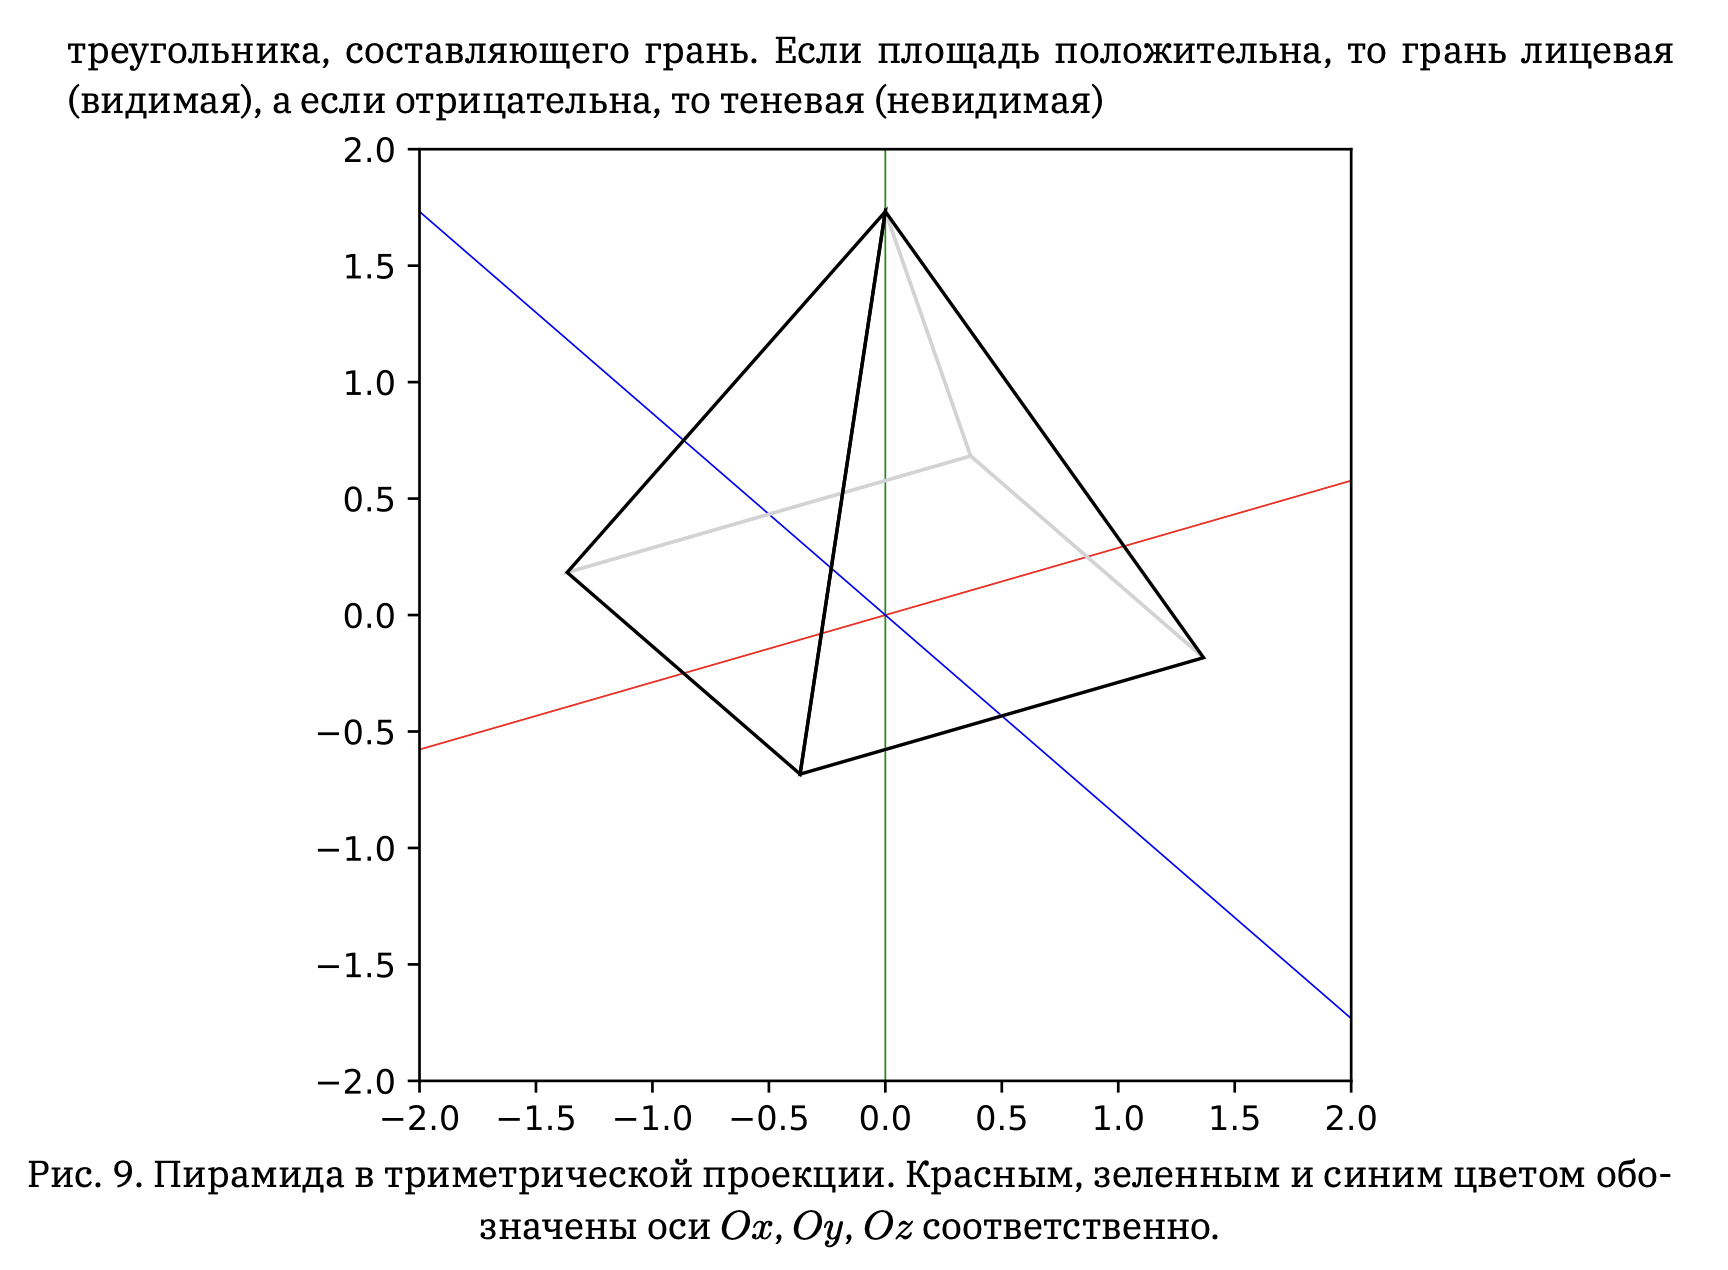

1. Теория: 

- Проектор — оператор, который отображает 3D-точку на плоскость (обычно матрица).
- Центр проекции — точка, из которой "смотрят" на объект (например, в центральной проекции).
- Плоскость проекции — двумерная плоскость, на которую проецируется объект.
- Классификация проекций:
    - Параллельные (аксонометрические): все лучи проекции параллельны.
    - Изометрическая: все три оси искажаются одинаково.
    - Диметрическая: две оси одинаково, третья — иначе.
    - Триметрическая: все три оси искажаются по-разному.
    - Перспективные: лучи сходятся в центре проекции.

In [4]:
# 2. Матрица триметрической проекции

import numpy as np

def trimetric_projection_matrix(alpha_deg, beta_deg):
    alpha = np.radians(alpha_deg)
    beta = np.radians(beta_deg)
    # Поворот вокруг Ox
    Rx = np.array([
        [1, 0, 0],
        [0, np.cos(alpha), -np.sin(alpha)],
        [0, np.sin(alpha),  np.cos(alpha)]
    ])
    # Поворот вокруг Oy
    Ry = np.array([
        [np.cos(beta), 0, np.sin(beta)],
        [0, 1, 0],
        [-np.sin(beta), 0, np.cos(beta)]
    ])
    # Общая матрица поворота
    R = Ry @ Rx
    # Проекция на плоскость XY
    P = np.array([
        [1, 0, 0],
        [0, 1, 0]
    ])
    # Итоговая матрица проекции
    M = P @ R
    return M, R

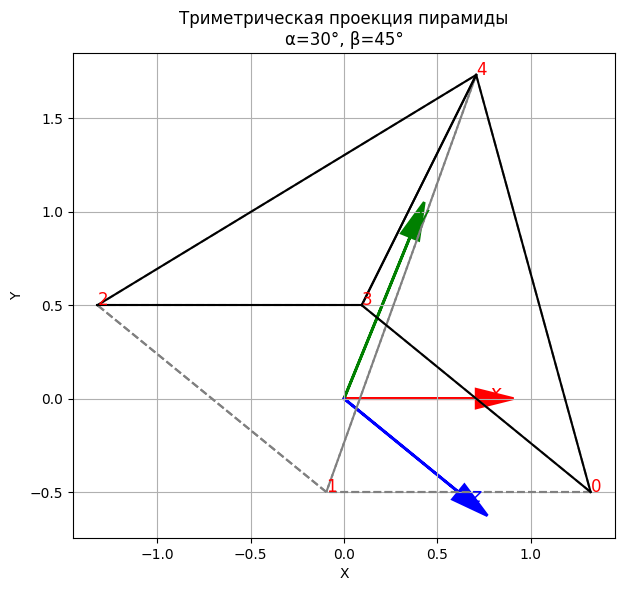

Коэффициенты искажения: fx=0.71, fy=0.94, fz=0.79


In [3]:
# 3. Визуализация пирамиды и осей в проекции

import matplotlib.pyplot as plt

# Вершины пирамиды (из предыдущих заданий)
pyramid_vertices = np.array([
    [1, 0, 1],
    [-1, 0, 1],
    [-1, 0, -1],
    [1, 0, -1],
    [0, 2, 0]
])

# Базисные векторы
basis = np.eye(3)

def project_and_plot_pyramid(alpha=30, beta=45, show_axes=True):
    M, R = trimetric_projection_matrix(alpha, beta)
    # Проецируем вершины пирамиды
    proj = (M @ pyramid_vertices.T).T
    # Проецируем базисные векторы
    basis_proj = (M @ basis.T).T

    # Грани пирамиды
    faces = [
        [0, 1, 2, 3],   # основание
        [0, 1, 4],
        [1, 2, 4],
        [2, 3, 4],
        [3, 0, 4]
    ]
    # Цвета для видимых и невидимых рёбер
    face_colors = ['gray', 'gray', 'gray', 'gray', 'gray']

    fig, ax = plt.subplots(figsize=(7,7))
    # Нарисуем рёбра
    for face in faces:
        pts = proj[face]
        # Определяем видимость грани через ориентированную площадь (по правилу правой руки)
        v1 = pts[1] - pts[0]
        v2 = pts[2] - pts[0]
        area = v1[0]*v2[1] - v1[1]*v2[0]
        color = 'black' if area > 0 else 'gray'
        linestyle = '-' if area > 0 else '--'
        # Для основания (четырёхугольник)
        if len(face) == 4:
            for i in range(4):
                ax.plot(*zip(pts[i], pts[(i+1)%4]), color=color, linestyle=linestyle)
        else:
            for i in range(3):
                ax.plot(*zip(pts[i], pts[(i+1)%3]), color=color, linestyle=linestyle)
    # Подписи вершин
    for i, (x, y) in enumerate(proj):
        ax.text(x, y, f'{i}', color='red', fontsize=12)
    # Оси
    if show_axes:
        colors = ['r', 'g', 'b']
        for i in range(3):
            ax.arrow(0, 0, basis_proj[i,0], basis_proj[i,1], head_width=0.1, head_length=0.2, fc=colors[i], ec=colors[i], linewidth=2)
            ax.text(basis_proj[i,0]*1.1, basis_proj[i,1]*1.1, f"${'xyz'[i]}$", color=colors[i], fontsize=14)
    ax.set_aspect('equal')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_title(f"Триметрическая проекция пирамиды\nα={alpha}°, β={beta}°")
    ax.grid(True)
    plt.show()
    # Коэффициенты искажения
    fx = np.linalg.norm(basis_proj[0])
    fy = np.linalg.norm(basis_proj[1])
    fz = np.linalg.norm(basis_proj[2])
    print(f"Коэффициенты искажения: fx={fx:.2f}, fy={fy:.2f}, fz={fz:.2f}")

project_and_plot_pyramid(30, 45)

In [7]:
# 4. Интерактивные ползунки для углов α и β

from ipywidgets import interact, FloatSlider

interact(
    project_and_plot_pyramid,
    alpha=FloatSlider(value=30, min=0, max=90, step=1, description='α (°)'),
    beta=FloatSlider(value=45, min=0, max=90, step=1, description='β (°)')
)

interactive(children=(FloatSlider(value=30.0, description='α (°)', max=90.0, step=1.0), FloatSlider(value=45.0…

<function __main__.project_and_plot_pyramid(alpha=30, beta=45, show_axes=True)>

In [9]:
# 5. Диметрическая проекция (один параметр — fz)

def project_and_plot_dimetric(fz=0.5):
    # Подберём угол β, чтобы fz = длина синей оси = нужное значение
    # Пусть α=0, тогда fz = |cos(β)|
    beta = np.degrees(np.arccos(fz))
    project_and_plot_pyramid(alpha=0, beta=beta)

from ipywidgets import FloatSlider
interact(
    project_and_plot_dimetric,
    fz=FloatSlider(value=0.5, min=0, max=1, step=0.01, description='fz')
)

interactive(children=(FloatSlider(value=0.5, description='fz', max=1.0, step=0.01), Output()), _dom_classes=('…

<function __main__.project_and_plot_dimetric(fz=0.5)>

In [12]:
# 6. Изометрическая проекция

def project_and_plot_isometric(option='A'):
    # Четыре варианта: ±α, ±β
    alpha = 35.264
    beta = 45
    if option == 'A':
        a, b = alpha, beta
    elif option == 'B':
        a, b = -alpha, beta
    elif option == 'C':
        a, b = alpha, -beta
    elif option == 'D':
        a, b = -alpha, -beta
    project_and_plot_pyramid(a, b)

from ipywidgets import SelectionSlider
interact(
    project_and_plot_isometric,
    option=SelectionSlider(options=['A', 'B', 'C', 'D'], value='A', description='Изометрия')
)

interactive(children=(SelectionSlider(description='Изометрия', options=('A', 'B', 'C', 'D'), value='A'), Outpu…

<function __main__.project_and_plot_isometric(option='A')>

In [ ]:
# 7. Невидимые рёбра

# В коде выше невидимые рёбра автоматически отображаются серым цветом или пунктиром, если площадь отрицательна.

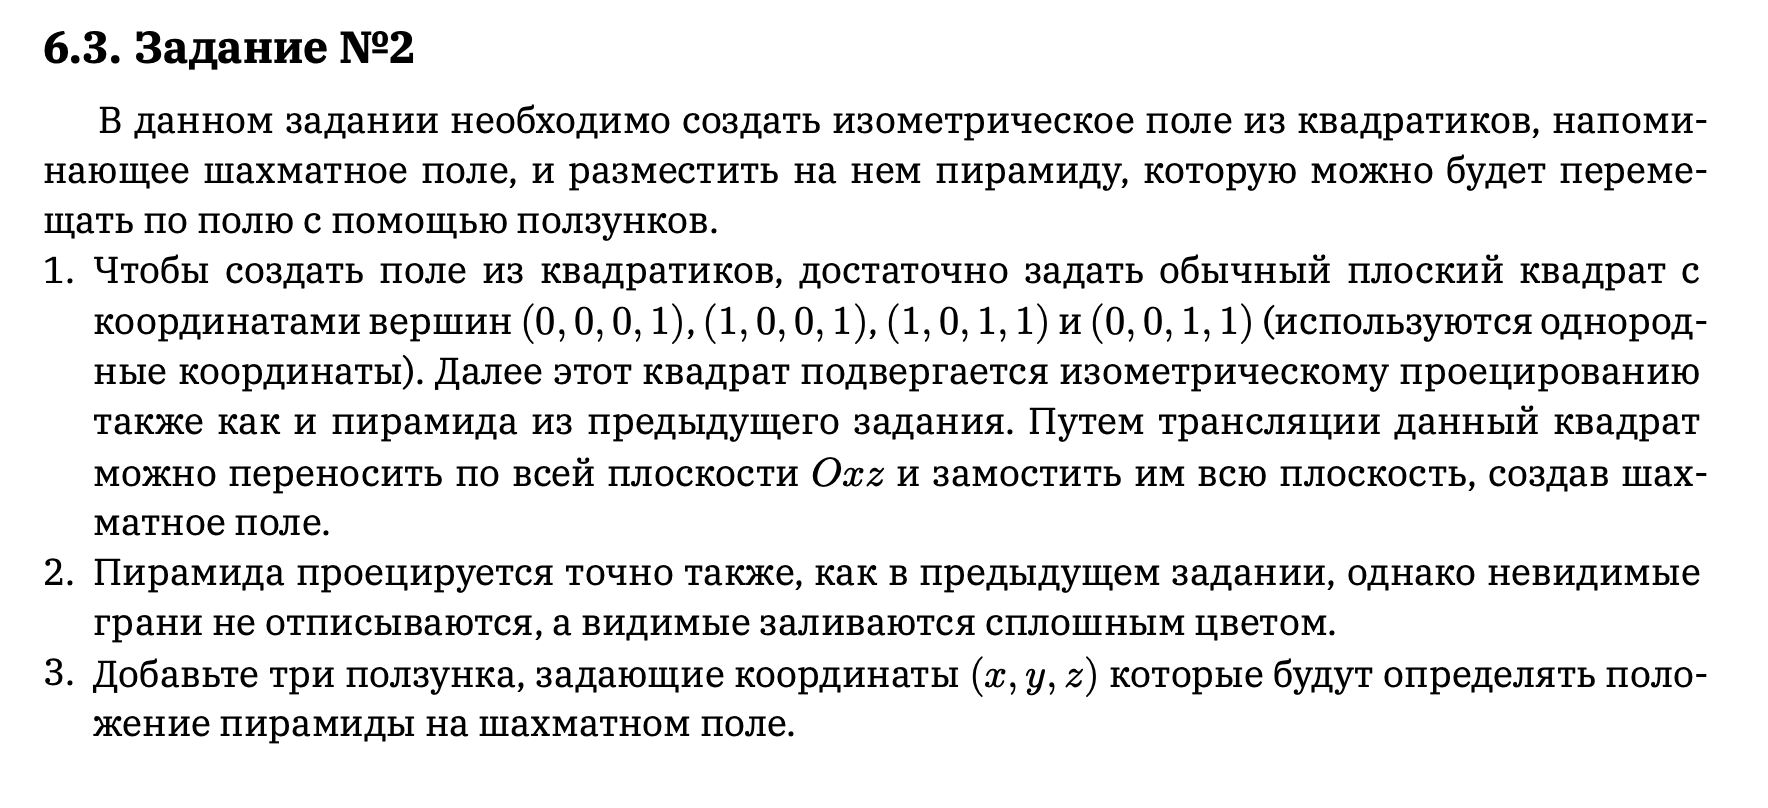

In [17]:
# 1. Функции для изометрической проекции

def isometric_projection_matrix():
    # Стандартные углы для изометрии
    alpha = np.radians(35.264)
    beta = np.radians(45)
    # Поворот вокруг Ox
    Rx = np.array([
        [1, 0, 0],
        [0, np.cos(alpha), -np.sin(alpha)],
        [0, np.sin(alpha),  np.cos(alpha)]
    ])
    # Поворот вокруг Oy
    Ry = np.array([
        [np.cos(beta), 0, np.sin(beta)],
        [0, 1, 0],
        [-np.sin(beta), 0, np.cos(beta)]
    ])
    # Общая матрица поворота
    R = Ry @ Rx
    # Проекция на плоскость XY
    P = np.array([
        [1, 0, 0],
        [0, 1, 0]
    ])
    # Итоговая матрица проекции
    M = P @ R
    return M

In [21]:
# 2. Функция для шахматного поля

def chessboard_field(n=8):
    # Квадрат в 3D (0,0,0)-(1,0,0)-(1,0,1)-(0,0,1)

    n = int(n)
    
    square = np.array([
        [0, 0, 0],
        [1, 0, 0],
        [1, 0, 1],
        [0, 0, 1]
    ])
    # Собираем все квадраты в поле
    squares = []
    colors = []
    for i in range(n):
        for j in range(n):
            sq = square + np.array([i, 0, j])
            squares.append(sq)
            colors.append('white' if (i+j)%2==0 else 'gray')
    return squares, colors

In [22]:
# 3. Вершины пирамиды

# Пирамида из предыдущих заданий
pyramid_vertices = np.array([
    [1, 0, 1],
    [-1, 0, 1],
    [-1, 0, -1],
    [1, 0, -1],
    [0, 2, 0]
])
# Грани пирамиды
pyramid_faces = [
    [0, 1, 2, 3],   # основание
    [0, 1, 4],
    [1, 2, 4],
    [2, 3, 4],
    [3, 0, 4]
]

In [25]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from ipywidgets import interact, IntSlider, FloatSlider

def plot_isometric_chess_and_pyramid(px=0.0, py=0.0, pz=0.0, n=8):
    M = isometric_projection_matrix()
    # 1. Рисуем шахматное поле
    squares, colors = chessboard_field(n)
    fig, ax = plt.subplots(figsize=(8,8))
    for sq, color in zip(squares, colors):
        sq_proj = (M @ sq.T).T
        ax.add_patch(Polygon(sq_proj, closed=True, facecolor=color, edgecolor='black', alpha=0.7))
    # 2. Рисуем пирамиду (сдвигаем на (px, py, pz))
    pyramid_shifted = pyramid_vertices + np.array([px, py, pz])
    proj = (M @ pyramid_shifted.T).T
    # Видимые грани (заливаем цветом)
    for face in pyramid_faces:
        pts = proj[face]
        ax.add_patch(Polygon(pts, closed=True, facecolor='orange', edgecolor='black', alpha=0.9))
    # Подписи вершин пирамиды
    for i, (x, y) in enumerate(proj):
        ax.text(x, y, f'{i}', color='red', fontsize=12)
    ax.set_aspect('equal')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_title("Изометрическое шахматное поле с пирамидой")
    ax.set_xlim(-5, 15)
    ax.set_ylim(-5, 15)
    plt.grid(True)
    plt.show()

interact(
    plot_isometric_chess_and_pyramid,
    px=FloatSlider(value=0, min=0, max=7, step=0.1, description='x'),
    py=FloatSlider(value=0, min=0, max=5, step=0.1, description='y'),
    pz=FloatSlider(value=0, min=0, max=7, step=0.1, description='z'),
    n=IntSlider(value=8, min=4, max=12, step=1, description='Размер поля')
)

interactive(children=(FloatSlider(value=0.0, description='x', max=7.0), FloatSlider(value=0.0, description='y'…

<function __main__.plot_isometric_chess_and_pyramid(px=0.0, py=0.0, pz=0.0, n=8)>

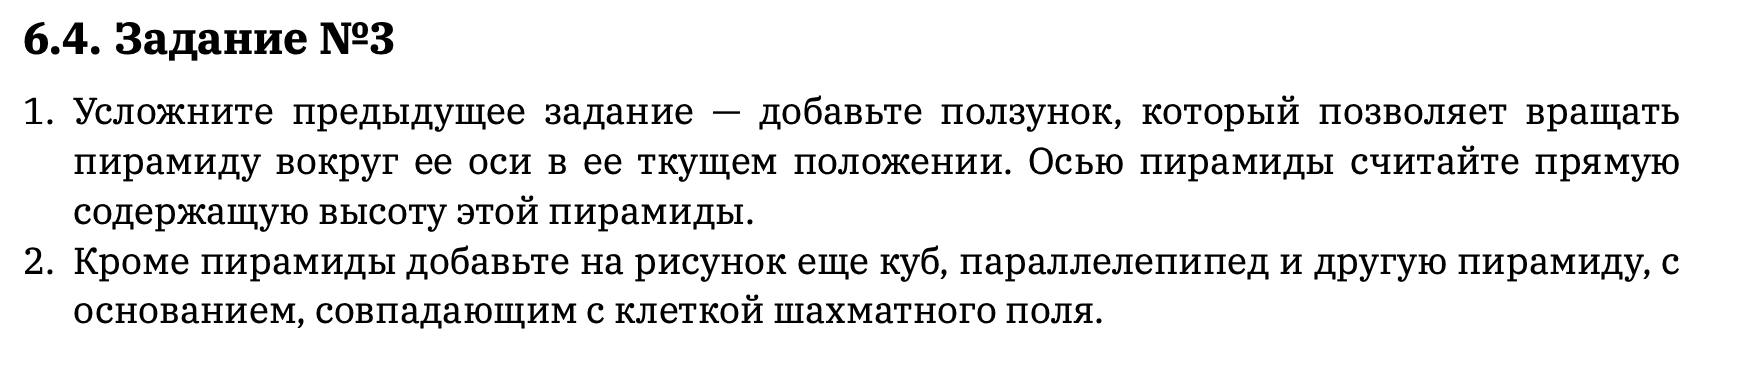

In [26]:
# 1. Вспомогательные функции для изометрической проекции и вращения

def isometric_projection_matrix():
    alpha = np.radians(35.264)
    beta = np.radians(45)
    Rx = np.array([
        [1, 0, 0],
        [0, np.cos(alpha), -np.sin(alpha)],
        [0, np.sin(alpha),  np.cos(alpha)]
    ])
    Ry = np.array([
        [np.cos(beta), 0, np.sin(beta)],
        [0, 1, 0],
        [-np.sin(beta), 0, np.cos(beta)]
    ])
    R = Ry @ Rx
    P = np.array([
        [1, 0, 0],
        [0, 1, 0]
    ])
    M = P @ R
    return M

def rotation_matrix(axis, theta_deg):
    theta = np.radians(theta_deg)
    axis = np.array(axis, dtype=float)
    axis = axis / np.linalg.norm(axis)
    x, y, z = axis
    c = np.cos(theta)
    s = np.sin(theta)
    C = 1 - c
    R = np.array([
        [c + x*x*C, x*y*C - z*s, x*z*C + y*s],
        [y*x*C + z*s, c + y*y*C, y*z*C - x*s],
        [z*x*C - y*s, z*y*C + x*s, c + z*z*C]
    ])
    return R

In [27]:
# 2. Геометрия фигур

# Пирамида (основание 2x2, высота 2)
pyramid_vertices = np.array([
    [1, 0, 1],
    [-1, 0, 1],
    [-1, 0, -1],
    [1, 0, -1],
    [0, 2, 0]
])
pyramid_faces = [
    [0, 1, 2, 3],   # основание
    [0, 1, 4],
    [1, 2, 4],
    [2, 3, 4],
    [3, 0, 4]
]

# Куб (размер 2, основание в (4,0,4))
cube_vertices = np.array([
    [4, 0, 4],
    [6, 0, 4],
    [6, 0, 6],
    [4, 0, 6],
    [4, 2, 4],
    [6, 2, 4],
    [6, 2, 6],
    [4, 2, 6]
])
cube_faces = [
    [0, 1, 2, 3], [4, 5, 6, 7], [0, 1, 5, 4],
    [1, 2, 6, 5], [2, 3, 7, 6], [3, 0, 4, 7]
]

# Параллелепипед (размер 2x1x3, основание в (7,0,2))
parallelepiped_vertices = np.array([
    [7, 0, 2],
    [9, 0, 2],
    [9, 0, 5],
    [7, 0, 5],
    [7, 1, 2],
    [9, 1, 2],
    [9, 1, 5],
    [7, 1, 5]
])
parallelepiped_faces = [
    [0, 1, 2, 3], [4, 5, 6, 7], [0, 1, 5, 4],
    [1, 2, 6, 5], [2, 3, 7, 6], [3, 0, 4, 7]
]

# Вторая пирамида (основание 1x1, высота 1, основание в (2,0,6))
pyramid2_vertices = np.array([
    [2, 0, 6],
    [3, 0, 6],
    [3, 0, 7],
    [2, 0, 7],
    [2.5, 1, 6.5]
])
pyramid2_faces = [
    [0, 1, 2, 3], [0, 1, 4], [1, 2, 4], [2, 3, 4], [3, 0, 4]
]

In [28]:
# 3. Шахматное поле

def chessboard_field(n=8):
    square = np.array([
        [0, 0, 0],
        [1, 0, 0],
        [1, 0, 1],
        [0, 0, 1]
    ])
    squares = []
    colors = []
    for i in range(n):
        for j in range(n):
            sq = square + np.array([i, 0, j])
            squares.append(sq)
            colors.append('white' if (i+j)%2==0 else 'gray')
    return squares, colors

In [32]:
# 4. Визуализация с вращением пирамиды вокруг её оси

def plot_scene(px=0.0, py=0.0, pz=0.0, theta=0.0, n=8):
    M = isometric_projection_matrix()
    # 1. Шахматное поле
    squares, colors = chessboard_field(n)
    fig, ax = plt.subplots(figsize=(9,9))
    all_points = []
    for sq, color in zip(squares, colors):
        sq_proj = (M @ sq.T).T
        all_points.append(sq_proj)
        ax.add_patch(Polygon(sq_proj, closed=True, facecolor=color, edgecolor='black', alpha=0.7))
    # 2. Пирамида (вращаем вокруг оси высоты)
    base_center = (pyramid_vertices[0] + pyramid_vertices[1] + pyramid_vertices[2] + pyramid_vertices[3]) / 4
    axis = pyramid_vertices[4] - base_center
    R = rotation_matrix(axis, theta)
    pyramid_shifted = (pyramid_vertices - base_center) @ R.T + base_center + np.array([px, py, pz])
    proj = (M @ pyramid_shifted.T).T
    all_points.append(proj)
    for face in pyramid_faces:
        pts = proj[face]
        ax.add_patch(Polygon(pts, closed=True, facecolor='orange', edgecolor='black', alpha=0.9))
    # 3. Куб
    cube_proj = (M @ cube_vertices.T).T
    all_points.append(cube_proj)
    for face in cube_faces:
        pts = cube_proj[face]
        ax.add_patch(Polygon(pts, closed=True, facecolor='lightblue', edgecolor='navy', alpha=0.7))
    # 4. Параллелепипед
    para_proj = (M @ parallelepiped_vertices.T).T
    all_points.append(para_proj)
    for face in parallelepiped_faces:
        pts = para_proj[face]
        ax.add_patch(Polygon(pts, closed=True, facecolor='lightgreen', edgecolor='green', alpha=0.7))
    # 5. Вторая пирамида
    pyramid2_proj = (M @ pyramid2_vertices.T).T
    all_points.append(pyramid2_proj)
    for face in pyramid2_faces:
        pts = pyramid2_proj[face]
        ax.add_patch(Polygon(pts, closed=True, facecolor='violet', edgecolor='purple', alpha=0.8))
    ax.set_aspect('equal')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    # --- Динамические границы ---
    all_points = np.vstack(all_points)
    margin = 1
    min_x, max_x = np.min(all_points[:,0])-margin, np.max(all_points[:,0])+margin
    min_y, max_y = np.min(all_points[:,1])-margin, np.max(all_points[:,1])+margin
    ax.set_xlim(min_x, max_x)
    ax.set_ylim(min_y, max_y)
    ax.set_title("Изометрическое поле с фигурами и вращающейся пирамидой")
    plt.grid(True)
    plt.show()

In [33]:
# 5. Интерактивный виджет

interact(
    plot_scene,
    px=FloatSlider(value=0, min=0, max=7, step=0.1, description='x'),
    py=FloatSlider(value=0, min=0, max=5, step=0.1, description='y'),
    pz=FloatSlider(value=0, min=0, max=7, step=0.1, description='z'),
    theta=FloatSlider(value=0, min=0, max=360, step=1, description='Вращение (°)'),
    n=IntSlider(value=8, min=4, max=12, step=1, description='Размер поля')
)

interactive(children=(FloatSlider(value=0.0, description='x', max=7.0), FloatSlider(value=0.0, description='y'…

<function __main__.plot_scene(px=0.0, py=0.0, pz=0.0, theta=0.0, n=8)>